# Forest-Change Detection: Source-Domain Data Preparation

## 1. Research objective

Investigate whether, and to what extent, phenology, forest-change event size and spatial pattern, and terrain contribute to the loss of performance when Earth observation foundation models are transferred between different forest environments.

The initial data-preparation stage focuses on dense humid tropical forests in the Amazon as the source domain. Models will subsequently be evaluated on contrasting target environments in Rwanda: dry woodland and evergreen montane forest.

## 2. Satellite imagery

**Primary source:** NASA Harmonized Landsat and Sentinel-2 (HLS) Version 2.0, accessed through NASA Earthdata using `earthaccess`.

**Required spectral bands:**
- Blue
- Green
- Red
- Near Infrared (NIR)
- Shortwave Infrared 1 (SWIR1)
- Shortwave Infrared 2 (SWIR2)

**Spatial resolution:** 30 m analysis grid.

**Required quality information:**
- Cloud and cloud-shadow masks.
- Valid-pixel and no-data masks.
- Acquisition dates.
- Surface reflectance values.
- Spatial coordinates and projection information.

## 3. Temporal sampling

Initial study period: five consecutive years.

For each year, collect imagery from:
- Dry season: a selected two-month window.
- Rainy season: a selected two-month window.

This gives 10 seasonal observation windows over five years.

Generate a cloud-screened median composite for each window, preserving dry- and rainy-season observations separately.

The exact months should be determined from the selected Amazon AOI's local seasonal calendar rather than assuming the entire Amazon has identical seasons.

## 4. Reference labels

**Candidate source:** MapBiomas Amazonia.

Investigate the availability of annual land-cover maps and forest/non-forest classes.

Potential use:
- Identify forest areas.
- Derive annual forest-cover transitions.
- Construct approximate forest-change masks by comparing consecutive years.
- Identify possible disturbance areas for subsequent event-size analysis.

Check class definitions, temporal coverage, spatial resolution, and licensing before using the labels.

Important: annual land-cover transitions are not automatically independently validated change-detection labels. Their suitability for pixel-level evaluation must be assessed.

## 5. Preprocessing

1. Define and load Amazon study-area polygons (AOIs).
2. Search and retrieve HLS observations intersecting the AOIs.
3. Filter observations by acquisition date and quality.
4. Apply

In [1]:
import pandas as pd
%pip install earthaccess
import earthaccess

Note: you may need to restart the kernel to use updated packages.


In [2]:
earthaccess.login()

In [3]:
# Coordinates are (longitude, latitude)
aoi_coordinates = [
    (-52.30, -7.00),  # Southwest
    (-52.20, -7.00),  # Southeast
    (-52.20, -6.90),  # Northeast
    (-52.30, -6.90),  # Northwest
    (-52.30, -7.00)   # Close polygon
]

granules = earthaccess.search_data(
    short_name="HLSL30",
    temporal=("2020-06-01", "2020-07-31"),
    polygon=aoi_coordinates,
    count=-1
)

print(f"Available granules: {len(granules)}")

Available granules: 4


In [4]:
for granule in granules:
    print(granule)

Collection: {'EntryTitle': 'HLS Landsat Operational Land Imager Surface Reflectance and TOA Brightness Daily Global 30m v2.0'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': -51.81720304, 'Latitude': -7.32501124}, {'Longitude': -51.81551959, 'Latitude': -6.33185892}, {'Longitude': -52.80800387, 'Latitude': -6.32935161}, {'Longitude': -52.81173411, 'Latitude': -7.32210679}, {'Longitude': -51.81720304, 'Latitude': -7.32501124}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2020-06-10T13:36:15.279Z', 'EndingDateTime': '2020-06-10T13:36:39.199Z'}}
Size(MB): 167.90003108978271
Data: ['https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSL30.020/HLS.L30.T22MCT.2020162T133615.v2.0/HLS.L30.T22MCT.2020162T133615.v2.0.B09.tif', 'https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSL30.020/HLS.L30.T22MCT.2020162T133615.v2.0/HLS.L30.T22MCT.2020162T133615.v2.0.B01.tif', 'https://data.lpdaac

## first inspection results

The search found four HLSL30 granules for the selected area. Each granule is one Landsat observation of a larger map tile that covers the area; it is not a small image clipped to the polygon.

The observations were made on June 10, June 26, July 12, and July 28, 2020. They are about 16 days apart. Each granule contains several files, including surface-reflectance bands and a quality mask. The data has a 30 m pixel size.

The search results show information and download links. They do not download the files. To use only the selected area, download the needed files and clip them to the polygon.

In [5]:
sentinel_granules = earthaccess.search_data(
    short_name="HLSS30",
    temporal=("2020-06-01", "2020-07-31"),
    polygon=aoi_coordinates,
    count=-1
)

print(f"Available HLSS30 granules: {len(sentinel_granules)}")

Available HLSS30 granules: 12


In [6]:
for granule in sentinel_granules:
    print(granule)

Collection: {'EntryTitle': 'HLS Sentinel-2 Multi-spectral Instrument Surface Reflectance Daily Global 30m v2.0'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': -51.81720304, 'Latitude': -7.32501124}, {'Longitude': -51.81551959, 'Latitude': -6.33185892}, {'Longitude': -52.80800387, 'Latitude': -6.32935161}, {'Longitude': -52.81173411, 'Latitude': -7.32210679}, {'Longitude': -51.81720304, 'Latitude': -7.32501124}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2020-06-02T13:54:24.410Z', 'EndingDateTime': '2020-06-02T13:54:24.410Z'}}
Size(MB): 220.37038135528564
Data: ['https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSS30.020/HLS.S30.T22MCT.2020154T135119.v2.0/HLS.S30.T22MCT.2020154T135119.v2.0.B08.tif', 'https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSS30.020/HLS.S30.T22MCT.2020154T135119.v2.0/HLS.S30.T22MCT.2020154T135119.v2.0.B07.tif', 'https://data.lpdaac.earthdataclou

## sentinel HLS results

The search found 12 HLSS30 granules. These are HLS products made from Sentinel-2 satellite images. Each granule is one observation of a map tile that covers the selected area; it is larger than the polygon and is not clipped to it.

The observations range from June 2 to July 27, 2020, with one listed every five days. Each granule includes several files, such as surface-reflectance bands and a quality mask (Fmask). The HLS products are provided at 30 m pixel size.

These are search results with file links, not downloaded images. Download the bands you need, then clip them to the polygon if you only want the selected area.

# 2. Compare the acquisition dates and spatial coverage.

,Sensor,Date,Tile,Footprint bounds (lon/lat),Days since previous (same sensor)
0,Sentinel-2 (HLSS30),2020-06-02,T22MCT,"(-52.81173411, -7.32501124, -51.81551959, -6.3...",NaN
1,Sentinel-2 (HLSS30),2020-06-07,T22MCT,"(-52.81173411, -7.32501124, -51.81551959, -6.3...",5.0
2,Landsat (HLSL30),2020-06-10,T22MCT,"(-52.81173411, -7.32501124, -51.81551959, -6.3...",NaN
3,Sentinel-2 (HLSS30),2020-06-12,T22MCT,"(-52.81173411, -7.32501124, -51.81551959, -6.3...",5.0
4,Sentinel-2 (HLSS30),2020-06-17,T22MCT,"(-52.81173411, -7.32501124, -51.81551959, -6.3...",5.0
5,Sentinel-2 (HLSS30),2020-06-22,T22MCT,"(-52.81173411, -7.32501124, -51.81551959, -6.3...",5.0
6,Landsat (HLSL30),2020-06-26,T22MCT,"(-52.81173411, -7.32501124, -51.81551959, -6.3...",16.0
7,Sentinel-2 (HLSS30),2020-06-27,T22MCT,"(-52.81173411, -7.32501124, -51.81551959, -6.3...",5.0
8,Sentinel-2 (HLSS30),2020-07-02,T22MCT,"(-52.81173411, -7.32501124, -51.81551959, -6.3...",5.0
9,Sentinel-2 (HLSS30),2020-07-07,T22MCT,"(-52.81173411, -7.32501124, -51.81551959, -6.3...",5.0


Observation counts:


,observations,first_date,last_date,unique_tiles
Sensor,,,,
Landsat (HLSL30),4,2020-06-10,2020-07-28,1
Sentinel-2 (HLSS30),12,2020-06-02,2020-07-27,1


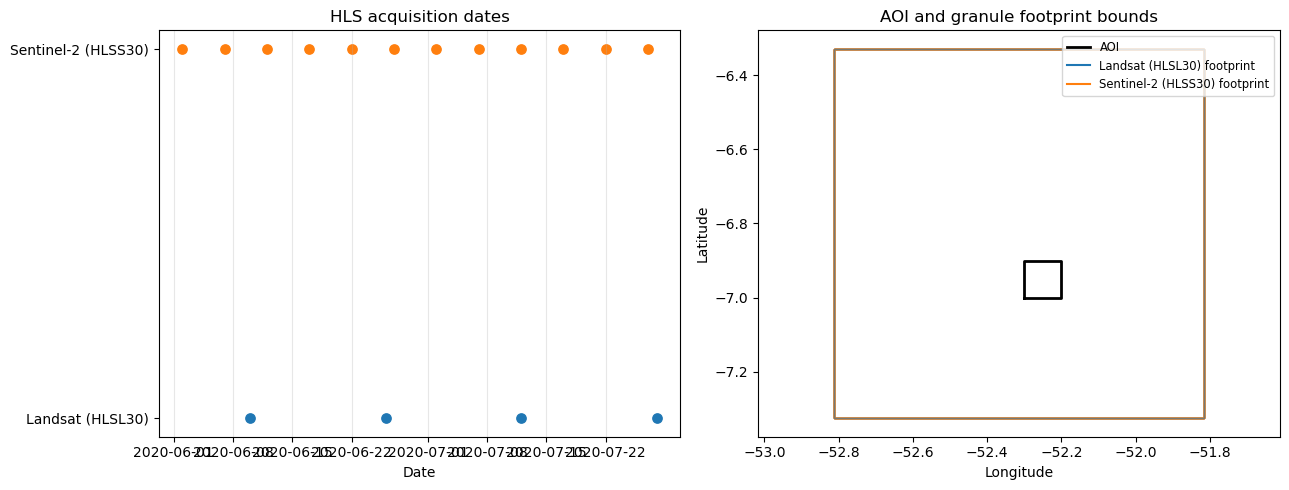

In [7]:
import re
from datetime import datetime, timedelta

import matplotlib.pyplot as plt

def walk_dicts(value):
    """Yield dictionaries nested in metadata."""
    if isinstance(value, dict):
        yield value
        for item in value.values():
            yield from walk_dicts(item)
    elif isinstance(value, (list, tuple)):
        for item in value:
            yield from walk_dicts(item)

def granule_metadata(g):
    """Try common earthaccess metadata access patterns."""
    candidates = [getattr(g, name, None) for name in ("umm", "meta", "_meta")]
    for name in ("umm", "meta"):
        try:
            candidates.append(g[name])
        except (TypeError, KeyError, AttributeError):
            pass
    candidates.append(getattr(g, "__dict__", {}))
    return [d for candidate in candidates for d in walk_dicts(candidate)]

def granule_info(g, sensor):
    metadata = granule_metadata(g)
    text = " ".join(str(d) for d in metadata) + " " + str(g)

    # Prefer the acquisition date in CMR temporal metadata; fall back to the
    # date in the HLS granule name (YYYY + day-of-year).
    date = None
    for d in metadata:
        for key in ("BeginningDateTime", "BeginningDate", "EndingDateTime"):
            value = d.get(key)
            if value:
                try:
                    date = datetime.fromisoformat(str(value).replace("Z", "+00:00")).date()
                    break
                except ValueError:
                    pass
        if date:
            break

    if date is None:
        match = re.search(r"\.(?:L30|S30)\.T\d{2}[A-Z]{3}\.(\d{4})(\d{3})T", text)
        if match:
            date = (datetime(int(match.group(1)), 1, 1)
                    + timedelta(days=int(match.group(2)) - 1)).date()
    if date is None:
        match = re.search(r"20\d{2}-\d{2}-\d{2}", text)
        date = datetime.strptime(match.group(), "%Y-%m-%d").date() if match else None

    tile_match = re.search(r"T\d{2}[A-Z]{3}", text)
    tile = tile_match.group() if tile_match else "Unknown"

    # Extract longitude/latitude pairs from UMM footprint metadata.
    points = []
    for d in metadata:
        if "Longitude" in d and "Latitude" in d:
            try:
                points.append((float(d["Longitude"]), float(d["Latitude"])))
            except (TypeError, ValueError):
                pass

    bounds = None
    if points:
        xs, ys = zip(*points)
        bounds = (min(xs), min(ys), max(xs), max(ys))

    return {
        "Sensor": sensor,
        "Date": date,
        "Tile": tile,
        "Footprint bounds (lon/lat)": bounds,
    }

records = (
    [granule_info(g, "Landsat (HLSL30)") for g in granules]
    + [granule_info(g, "Sentinel-2 (HLSS30)") for g in sentinel_granules]
)

# Convert Python date objects and strings to pandas datetimes before using .dt.
comparison = pd.DataFrame(records)
comparison["Date"] = pd.to_datetime(comparison["Date"], errors="coerce")
comparison = comparison.sort_values(["Date", "Sensor"]).reset_index(drop=True)
comparison["Days since previous (same sensor)"] = (
    comparison.groupby("Sensor")["Date"].diff().dt.days
)

display(comparison)

print("Observation counts:")
display(comparison.groupby("Sensor").agg(
    observations=("Date", "count"),
    first_date=("Date", "min"),
    last_date=("Date", "max"),
    unique_tiles=("Tile", "nunique"),
))

# Plot acquisition dates and spatial bounding boxes.
fig, (ax_dates, ax_map) = plt.subplots(1, 2, figsize=(13, 5))

colors = {"Landsat (HLSL30)": "tab:blue", "Sentinel-2 (HLSS30)": "tab:orange"}
for sensor, group in comparison.groupby("Sensor"):
    dates = pd.to_datetime(group["Date"])
    ax_dates.scatter(dates, [sensor] * len(group), label=sensor,
                     color=colors[sensor], s=45)
ax_dates.set_title("HLS acquisition dates")
ax_dates.set_xlabel("Date")
ax_dates.grid(axis="x", alpha=0.3)

aoi_x, aoi_y = zip(*aoi_coordinates)
ax_map.plot(aoi_x, aoi_y, color="black", linewidth=2, label="AOI")

for _, row in comparison.dropna(subset=["Footprint bounds (lon/lat)"]).iterrows():
    xmin, ymin, xmax, ymax = row["Footprint bounds (lon/lat)"]
    ax_map.add_patch(plt.Rectangle(
        (xmin, ymin), xmax - xmin, ymax - ymin,
        fill=False, edgecolor=colors[row["Sensor"]], alpha=0.6
    ))
for sensor, color in colors.items():
    ax_map.plot([], [], color=color, label=f"{sensor} footprint")

ax_map.set_title("AOI and granule footprint bounds")
ax_map.set_xlabel("Longitude")
ax_map.set_ylabel("Latitude")
ax_map.legend(fontsize="small")
ax_map.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.show()


## Summary: HLS acquisition-date and coverage check

A rectangular Amazon AOI was defined near **(-52.3°, -7.0°)**. The NASA HLS Version 2.0 search for **June 1–July 31, 2020** returned **4 Landsat (HLSL30)** and **12 Sentinel-2 (HLSS30)** granules. All are associated with tile **T22MCT**, whose reported footprint bounds cover the AOI. Landsat observations span **June 10–July 28**, about 16 days apart; Sentinel-2 observations span **June 2–July 27**, about 5 days apart.

### What the comparison tells us about the research

The denser Sentinel-2 acquisition schedule, combined with Landsat observations, offers more opportunities to sample changing forest conditions. This is relevant to the research because differences in seasonal timing and observation availability may affect the quality and comparability of forest-change inputs used to evaluate model transfer across forest environments. HLS provides a common 30 m analysis grid, which supports combining observations from the two sensors.

This comparison establishes **initial data availability and tile-level spatial coverage** for one Amazon AOI and one two-month period. It does **not** establish that the observations are cloud-free, provide sufficient valid pixels, or demonstrate anything about model performance or transferability. Those questions require quality-mask screening and analysis of the imagery and reference labels.

The search also covers only part of one year. It is not enough to assess the research’s five-year, dry- and rainy-season sampling plan. The next steps are to retrieve the required bands and quality masks, screen for usable pixels, clip the imagery to the AOI, and repeat the assessment for the selected seasonal windows and years.

## 3. Download pilot HLS bands and quality layers

Download only B02, B03, B04, B05, B06, B07, and Fmask for the pilot observations. These files are tile-sized; the AOI clipping happens after download.

In [9]:
from pathlib import Path
from urllib.parse import unquote, urlsplit
import re

import earthaccess

DOWNLOAD_DIR = Path("data/hls_pilot")
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

required_assets = {"B02", "B03", "B04", "B05", "B06", "B07", "Fmask"}
all_granules = list(granules) + list(sentinel_granules)

In [ ]:
from pathlib import Path
from urllib.parse import unquote, urlsplit
import re

import earthaccess

DOWNLOAD_DIR = Path("data/hls_pilot")
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

required_assets = {"B02", "B03", "B04", "B05", "B06", "B07", "Fmask"}
all_granules = list(granules) + list(sentinel_granules)

urls_to_download = set()
for granule in all_granules:
    try:
        # Default to the HTTPS download links that work from a local machine.
        links = granule.data_links()
        if not links:
            links = granule.data_links(access="direct")
    except TypeError:
        links = granule.data_links()

    for url in links:
        if url.startswith("s3://"):
            continue
        filename = unquote(Path(urlsplit(url).path).name)
        match = re.search(r"\.([^.]+)\.tif$", filename, flags=re.IGNORECASE)
        if match and match.group(1) in required_assets:
            urls_to_download.add(url)

print(f"Selected {len(urls_to_download)} band/quality files.")
if not urls_to_download:
    raise RuntimeError("No matching HLS download links found; inspect granule.data_links().")

downloaded = earthaccess.download(
    sorted(urls_to_download),
    local_path=str(DOWNLOAD_DIR),
)
print(f"Download call returned {len(downloaded)} file(s).")


Selected 112 band/quality files.


QUEUEING TASKS | :   0%|          | 0/112 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/112 [00:00<?, ?it/s]

Trying to download the remaining images

In [15]:
%pip install rasterio
import rasterio

existing_by_name = {
    path.name: path
    for path in DOWNLOAD_DIR.rglob("*.tif")
}
missing_urls = []

# Rebuild the target list if this cell is run before the earlier download cell
if "urls_to_download" not in globals():
    urls_to_download = set()
    for granule in all_granules:
        try:
            links = granule.data_links()
            if not links:
                links = granule.data_links(access="direct")
        except TypeError:
            links = granule.data_links()

        for url in links:
            if url.startswith("s3://"):
                continue
            filename = unquote(Path(urlsplit(url).path).name)
            match = re.search(r"\.([^.]+)\.tif$", filename, flags=re.IGNORECASE)
            if match and match.group(1) in required_assets:
                urls_to_download.add(url)

# Keep only files that are missing or unreadable
missing_urls = []
for url in sorted(urls_to_download):
    filename = unquote(Path(urlsplit(url).path).name)
    path = existing_by_name.get(filename)
    if path is None:
        missing_urls.append(url)
        continue
    try:
        with rasterio.open(path) as src:
            _ = src.profile
    except Exception:
        missing_urls.append(url)
if "urls_to_download" not in globals():
    urls_to_download = set()
    for granule in all_granules:
        try:
            links = granule.data_links()
            if not links:
                links = granule.data_links(access="direct")
        except TypeError:
            links = granule.data_links()

        for url in links:
            if url.startswith("s3://"):
                continue
            filename = unquote(Path(urlsplit(url).path).name)
            match = re.search(r"\.([^.]+)\.tif$", filename, flags=re.IGNORECASE)
            if match and match.group(1) in required_assets:
                urls_to_download.add(url)

for url in sorted(urls_to_download):
    filename = unquote(Path(urlsplit(url).path).name)
    local_file = existing_by_name.get(filename)

    if local_file is not None:
        try:
            # Check that the existing file is readable and not truncated
            with rasterio.open(local_file) as src:
                src.read(1)
            continue
        except Exception:
            if local_file.exists():
                local_file.unlink(missing_ok=True)

    missing_urls.append(url)

print(f"Assets still needing download: {len(missing_urls)}")
if missing_urls:
    downloaded = earthaccess.download(
        missing_urls,
        local_path=str(DOWNLOAD_DIR),
    )
    print(f"Download call returned {len(downloaded)} file(s).")
else:
    print("All requested assets are already present and readable.")

Note: you may need to restart the kernel to use updated packages.
Assets still needing download: 12


QUEUEING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/12 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/12 [00:00<?, ?it/s]

Download call returned 12 file(s).


### Check 1: Verify downloaded assets

Each observation should have all six reflectance bands and one Fmask layer before processing.

In [16]:
asset_paths = {}
for path in DOWNLOAD_DIR.rglob("*.tif"):
    parts = path.name.split(".")
    if len(parts) >= 3 and parts[-2] in required_assets:
        product_key = ".".join(parts[:-2])
        asset_paths.setdefault(product_key, {})[parts[-2]] = path

expected = required_assets
incomplete = {
    key: sorted(expected - set(assets))
    for key, assets in asset_paths.items()
    if expected - set(assets)
}
print(f"Observations found: {len(asset_paths)}")
print(f"Complete observations: {len(asset_paths) - len(incomplete)}")
if incomplete:
    display(pd.DataFrame(
        [{"observation": key, "missing_assets": missing}
         for key, missing in incomplete.items()]
    ))
if not asset_paths or incomplete:
    raise RuntimeError("Download is incomplete; resolve missing assets before continuing.")

Observations found: 16
Complete observations: 16


## 4. Mask invalid pixels and clip observations to the AOI

Fmask is a bit field. The mask below excludes fill, cirrus, cloud, adjacent-to-cloud, cloud-shadow, and snow/ice pixels. The AOI polygon is transformed to the raster CRS, and observations are aligned to one common 30 m grid.

In [21]:
# If needed, install once, then restart the notebook kernel:
%pip install shapely

import numpy as np
import rasterio
from rasterio.features import geometry_mask
from rasterio.warp import reproject, transform_geom
from rasterio.enums import Resampling
from shapely.geometry import Polygon, mapping
from rasterio.mask import mask as raster_mask


aoi_polygon = Polygon(aoi_coordinates)
product_keys = sorted(asset_paths)

# Use the first B02 granule to define the shared AOI grid.
with rasterio.open(asset_paths[product_keys[0]]["B02"]) as src:
    aoi_in_crs = transform_geom("EPSG:4326", src.crs, mapping(aoi_polygon))
    _, ref_transform = rasterio.mask.mask(
        src, [aoi_in_crs], crop=True, filled=True
    )
    # Recalculate the cropped dimensions and transform.
    from rasterio.mask import mask as raster_mask
    _, ref_transform = raster_mask(src, [aoi_in_crs], crop=True, filled=True)
    ref_crs = src.crs
    ref_height, ref_width = raster_mask(
        src, [aoi_in_crs], crop=True, filled=True
    )[0].shape[1:]

aoi_pixels = geometry_mask(
    [aoi_in_crs],
    out_shape=(ref_height, ref_width),
    transform=ref_transform,
    invert=True,
)

# Fmask bits 0–4: cirrus, cloud, adjacent cloud, shadow, snow/ice.
F_MASK_BITS = 0b00011111
band_names = ["B02", "B03", "B04", "B05", "B06", "B07"]
observations = {}
coverage_rows = []

for key in product_keys:
    assets = asset_paths[key]
    band_arrays = []

    for band in band_names:
        dest = np.full((ref_height, ref_width), np.nan, dtype=np.float32)
        with rasterio.open(assets[band]) as src:
            reproject(
                source=rasterio.band(src, 1),
                destination=dest,
                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=src.nodata if src.nodata is not None else -9999,
                dst_transform=ref_transform,
                dst_crs=ref_crs,
                dst_nodata=np.nan,
                resampling=Resampling.nearest,
            )
        # HLS surface reflectance scale factor is 0.0001.
        dest *= 0.0001
        band_arrays.append(dest)

    fmask = np.full((ref_height, ref_width), 255, dtype=np.uint8)
    with rasterio.open(assets["Fmask"]) as src:
        reproject(
            source=rasterio.band(src, 1),
            destination=fmask,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            dst_nodata=255,
            resampling=Resampling.nearest,
        )

    stack = np.stack(band_arrays)  # bands × rows × columns
    invalid_fmask = (fmask == 255) | ((fmask & F_MASK_BITS) != 0)
    valid = aoi_pixels & ~invalid_fmask & np.all(np.isfinite(stack), axis=0)

    stack[:, ~valid] = np.nan
    observations[key] = {"bands": stack, "valid": valid}

    coverage = 100 * valid.sum() / aoi_pixels.sum()
    coverage_rows.append({
        "Observation": key,
        "Valid AOI pixels": int(valid.sum()),
        "AOI pixels": int(aoi_pixels.sum()),
        "Valid coverage (%)": coverage,
    })

coverage_df = pd.DataFrame(coverage_rows).sort_values("Observation")
display(coverage_df)

Note: you may need to restart the kernel to use updated packages.


,Observation,Valid AOI pixels,AOI pixels,Valid coverage (%)
0,HLS.L30.T22MCT.2020162T133615.v2.0,134339,135759,98.954029
1,HLS.L30.T22MCT.2020178T133623.v2.0,135759,135759,100.000000
2,HLS.L30.T22MCT.2020194T133630.v2.0,135039,135759,99.469648
3,HLS.L30.T22MCT.2020210T133635.v2.0,135759,135759,100.000000
4,HLS.S30.T22MCT.2020154T135119.v2.0,91411,135759,67.333289
5,HLS.S30.T22MCT.2020159T135121.v2.0,113556,135759,83.645283
6,HLS.S30.T22MCT.2020164T135119.v2.0,93559,135759,68.915505
7,HLS.S30.T22MCT.2020169T135121.v2.0,135543,135759,99.840895
8,HLS.S30.T22MCT.2020174T135119.v2.0,135541,135759,99.839421
9,HLS.S30.T22MCT.2020179T135121.v2.0,135082,135759,99.501322


### Check 2: Review valid-pixel coverage

Coverage is the percentage of AOI pixels with valid data in all six bands after Fmask screening. Low coverage indicates that an observation contributes little usable imagery; the percentage should be reviewed before interpreting the composite.

In [23]:
import warnings


all_stacks = np.stack([observations[key]["bands"] for key in product_keys])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    median_composite = np.nanmedian(all_stacks, axis=0)

valid_observation_count = np.sum(
    np.stack([observations[key]["valid"] for key in product_keys]),
    axis=0,
)
median_composite[:, ~aoi_pixels] = np.nan

OUTPUT_DIR = Path("data/hls_pilot/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the six-band median composite; NaN is written as -9999.
profile = {
    "driver": "GTiff",
    "height": ref_height,
    "width": ref_width,
    "count": len(band_names),
    "dtype": "float32",
    "crs": ref_crs,
    "transform": ref_transform,
    "nodata": -9999.0,
    "compress": "deflate",
}
composite_path = OUTPUT_DIR / "hls_pilot_median.tif"
with rasterio.open(composite_path, "w", **profile) as dst:
    dst.write(np.nan_to_num(median_composite, nan=-9999.0))
    for index, band in enumerate(band_names, start=1):
        dst.set_band_description(index, band)

count_profile = {**profile, "count": 1, "dtype": "uint16", "nodata": 0}
count_path = OUTPUT_DIR / "valid_observation_count.tif"
with rasterio.open(count_path, "w", **count_profile) as dst:
    dst.write(valid_observation_count.astype(np.uint16), 1)

coverage_path = OUTPUT_DIR / "valid_pixel_coverage.csv"
coverage_df.to_csv(coverage_path, index=False)

print(f"Composite saved to: {composite_path}")
print(f"Valid-observation count saved to: {count_path}")
print(f"Coverage table saved to: {coverage_path}")
print(
    "AOI pixels with at least one valid observation:",
    f"{100 * np.count_nonzero((valid_observation_count > 0) & aoi_pixels) / aoi_pixels.sum():.2f}%"
)

Composite saved to: data\hls_pilot\processed\hls_pilot_median.tif
Valid-observation count saved to: data\hls_pilot\processed\valid_observation_count.tif
Coverage table saved to: data\hls_pilot\processed\valid_pixel_coverage.csv
AOI pixels with at least one valid observation: 100.00%


## Summary of pilot findings and status

### Search and spatial coverage
The pilot area is a rectangular AOI near **(-52.3°, -7.0°)** in the Amazon. The HLS search for **June 1–July 31, 2020** returned **4 HLSL30 Landsat granules** and **12 HLSS30 Sentinel-2 granules**. The notebook reports that they cover tile **T22MCT**, which includes the AOI.

The Landsat observations span **June 10–July 28**, at roughly 16-day intervals. The Sentinel-2 observations span **June 2–July 27**, with acquisitions listed about every five days. These search results show data availability and tile-level coverage; they do not establish cloud-free coverage or sufficient usable pixels.

### Data preparation
The download request targets six reflectance bands (**B02–B07**) and **Fmask** for each observation. The asset check previously raised an incomplete-download error. Until **Check 1** passes, the inputs should not be treated as complete.

The preprocessing cell also encountered a `rasterio.mask` import error. Therefore, the notebook has **not yet produced confirmed valid-pixel coverage, a median composite, or output files**. Those results should be added after the corrected preprocessing cell runs successfully.

### Relevance and limitations
The different acquisition schedules provide multiple opportunities to sample seasonal forest conditions, and HLS offers a common 30 m grid for the two sensors. However, this is only a two-month pilot in one year and one AOI. It does not evaluate model performance or transferability, and it is not sufficient for the planned five-year, dry- and rainy-season analysis.

**Next steps:** complete and verify the downloads, run the corrected masking and clipping workflow, review valid-pixel coverage, then repeat the analysis for the selected seasonal windows and years.

In [24]:
import re
from datetime import datetime
import pandas as pd
import rasterio

def parse_hls_date(granule_id):
    match = re.search(r"\.(\d{4})(\d{3})T", granule_id)
    if not match:
        return None
    year, doy = int(match.group(1)), int(match.group(2))
    try:
        return datetime.strptime(f"{year}{doy}", "%Y%j").date()
    except ValueError:
        return None

def detect_sensor(granule_id):
    if granule_id.startswith("HLS.L30"):
        return "HLSL30"
    if granule_id.startswith("HLS.S30"):
        return "HLSS30"
    return "Unknown"

# Build manifest for all known granules, including those that are missing locally
granule_ids = []
if "product_keys" in globals():
    granule_ids.extend(product_keys)
if "asset_paths" in globals():
    granule_ids.extend(asset_paths.keys())
granule_ids = sorted(set(granule_ids))

manifest_rows = []

for granule_id in granule_ids:
    assets = asset_paths.get(granule_id, {}) if "asset_paths" in globals() else {}
    available_assets = set(assets.keys()) & required_assets
    available_bands = sorted(available_assets - {"Fmask"})
    fmask_file = assets.get("Fmask")
    fmask_exists = fmask_file is not None

    missing_assets = sorted(required_assets - available_assets)
    download_status = "complete" if not missing_assets else "incomplete"

    # Important: verify that every required file can actually be opened and read
    read_ok = True
    for asset_name in sorted(required_assets):
        path = assets.get(asset_name)
        if path is None:
            read_ok = False
            break
        try:
            with rasterio.open(path) as src:
                src.read(1)
        except Exception:
            read_ok = False
            break
    read_status = "pass" if read_ok else "fail"

    tile_match = re.search(r"T\d{2}[A-Z]{3}", granule_id)
    tile = tile_match.group(0) if tile_match else "Unknown"

    manifest_rows.append({
        "Granule ID": granule_id,
        "Sensor": detect_sensor(granule_id),
        "Acquisition date": parse_hls_date(granule_id),
        "Tile": tile,
        "Bands": ", ".join(available_bands) if available_bands else "None",
        "Fmask": "Yes" if fmask_exists else "No",
        "Download status": download_status,
        "Read status": read_status,
    })

manifest = pd.DataFrame(
    manifest_rows,
    columns=[
        "Granule ID",
        "Sensor",
        "Acquisition date",
        "Tile",
        "Bands",
        "Fmask",
        "Download status",
        "Read status",
    ]
).sort_values(["Sensor", "Acquisition date", "Granule ID"]).reset_index(drop=True)

display(manifest)

,Granule ID,Sensor,Acquisition date,Tile,Bands,Fmask,Download status,Read status
0,HLS.L30.T22MCT.2020162T133615.v2.0,HLSL30,2020-06-10,T22MCT,"B02, B03, B04, B05, B06, B07",Yes,complete,pass
1,HLS.L30.T22MCT.2020178T133623.v2.0,HLSL30,2020-06-26,T22MCT,"B02, B03, B04, B05, B06, B07",Yes,complete,pass
2,HLS.L30.T22MCT.2020194T133630.v2.0,HLSL30,2020-07-12,T22MCT,"B02, B03, B04, B05, B06, B07",Yes,complete,pass
3,HLS.L30.T22MCT.2020210T133635.v2.0,HLSL30,2020-07-28,T22MCT,"B02, B03, B04, B05, B06, B07",Yes,complete,pass
4,HLS.S30.T22MCT.2020154T135119.v2.0,HLSS30,2020-06-02,T22MCT,"B02, B03, B04, B05, B06, B07",Yes,complete,pass
5,HLS.S30.T22MCT.2020159T135121.v2.0,HLSS30,2020-06-07,T22MCT,"B02, B03, B04, B05, B06, B07",Yes,complete,pass
6,HLS.S30.T22MCT.2020164T135119.v2.0,HLSS30,2020-06-12,T22MCT,"B02, B03, B04, B05, B06, B07",Yes,complete,pass
7,HLS.S30.T22MCT.2020169T135121.v2.0,HLSS30,2020-06-17,T22MCT,"B02, B03, B04, B05, B06, B07",Yes,complete,pass
8,HLS.S30.T22MCT.2020174T135119.v2.0,HLSS30,2020-06-22,T22MCT,"B02, B03, B04, B05, B06, B07",Yes,complete,pass
9,HLS.S30.T22MCT.2020179T135121.v2.0,HLSS30,2020-06-27,T22MCT,"B02, B03, B04, B05, B06, B07",Yes,complete,pass


In [25]:
manifest.to_csv(
    "data/hls_pilot/data_manifest.csv",
    index=False
)

# 2. Data Quality

In [26]:
import pandas as pd

task_plan = pd.DataFrame(
    [
        {"Priority": 1, "Task": "Check CRS, resolution, dimensions and alignment", "Stage": 2.2},
        {"Priority": 2, "Task": "Apply Fmask and cloud masking", "Stage": 2.2},
        {"Priority": 3, "Task": "Clip observations to the AOI", "Stage": 2.2},
        {"Priority": 4, "Task": "Calculate valid-pixel coverage per acquisition", "Stage": 2.2},
        {"Priority": 5, "Task": "Inspect temporal coverage and missing observations", "Stage": 2.2},
        {"Priority": 6, "Task": "Generate a median composite for visual inspection", "Stage": 2.2},
    ]
)

display(task_plan)

,Priority,Task,Stage
0,1,"Check CRS, resolution, dimensions and alignment",2.2
1,2,Apply Fmask and cloud masking,2.2
2,3,Clip observations to the AOI,2.2
3,4,Calculate valid-pixel coverage per acquisition,2.2
4,5,Inspect temporal coverage and missing observat...,2.2
5,6,Generate a median composite for visual inspection,2.2


## CRS, resolution, alignemnet

In [27]:
import pandas as pd
import rasterio

# Use the first B02 image as the reference grid
ref_key = next(k for k in product_keys if k in asset_paths and "B02" in asset_paths[k])
ref_path = asset_paths[ref_key]["B02"]

with rasterio.open(ref_path) as ref_src:
    ref_crs = ref_src.crs
    ref_width, ref_height = ref_src.width, ref_src.height
    ref_res = ref_src.res
    ref_transform = ref_src.transform

rows = []

for key, assets in asset_paths.items():
    for band_name, path in assets.items():
        with rasterio.open(path) as src:
            same_crs = src.crs == ref_crs
            same_size = (src.width, src.height) == (ref_width, ref_height)
            same_res = src.res == ref_res
            same_transform = src.transform == ref_transform

            rows.append({
                "Observation": key,
                "Asset": band_name,
                "CRS": str(src.crs),
                "Match CRS": same_crs,
                "Width": src.width,
                "Height": src.height,
                "Match size": same_size,
                "Resolution": src.res,
                "Match resolution": same_res,
                "Transform matches reference": same_transform,
                "Bounds": src.bounds,
            })

grid_check = pd.DataFrame(rows)
display(grid_check)

# Summary
mismatches = grid_check[
    (~grid_check["Match CRS"]) |
    (~grid_check["Match size"]) |
    (~grid_check["Match resolution"]) |
    (~grid_check["Transform matches reference"])
]

if mismatches.empty:
    print("All rasters match the reference B02 grid in CRS, size, resolution, and transform.")
else:
    print("These rasters do not match the reference grid:")
    display(mismatches)

,Observation,Asset,CRS,Match CRS,Width,Height,Match size,Resolution,Match resolution,Transform matches reference,Bounds
0,HLS.L30.T22MCT.2020162T133615.v2.0,B02,"PROJCS[""UTM Zone 22, Northern Hemisphere"",GEOG...",True,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
1,HLS.L30.T22MCT.2020162T133615.v2.0,B03,"PROJCS[""UTM Zone 22, Northern Hemisphere"",GEOG...",True,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
2,HLS.L30.T22MCT.2020162T133615.v2.0,B04,"PROJCS[""UTM Zone 22, Northern Hemisphere"",GEOG...",True,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
3,HLS.L30.T22MCT.2020162T133615.v2.0,B05,"PROJCS[""UTM Zone 22, Northern Hemisphere"",GEOG...",True,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
4,HLS.L30.T22MCT.2020162T133615.v2.0,B06,"PROJCS[""UTM Zone 22, Northern Hemisphere"",GEOG...",True,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
...,...,...,...,...,...,...,...,...,...,...,...
107,HLS.S30.T22MCT.2020209T135121.v2.0,B04,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
108,HLS.S30.T22MCT.2020209T135121.v2.0,B05,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
109,HLS.S30.T22MCT.2020209T135121.v2.0,B06,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
110,HLS.S30.T22MCT.2020209T135121.v2.0,B07,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"


These rasters do not match the reference grid:


,Observation,Asset,CRS,Match CRS,Width,Height,Match size,Resolution,Match resolution,Transform matches reference,Bounds
28,HLS.S30.T22MCT.2020154T135119.v2.0,B02,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
29,HLS.S30.T22MCT.2020154T135119.v2.0,B03,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
30,HLS.S30.T22MCT.2020154T135119.v2.0,B04,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
31,HLS.S30.T22MCT.2020154T135119.v2.0,B05,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
32,HLS.S30.T22MCT.2020154T135119.v2.0,B06,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
...,...,...,...,...,...,...,...,...,...,...,...
107,HLS.S30.T22MCT.2020209T135121.v2.0,B04,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
108,HLS.S30.T22MCT.2020209T135121.v2.0,B05,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
109,HLS.S30.T22MCT.2020209T135121.v2.0,B06,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"
110,HLS.S30.T22MCT.2020209T135121.v2.0,B07,EPSG:32622,False,3660,3660,True,"(30.0, 30.0)",True,True,"(300000.0, -809760.0, 409800.0, -699960.0)"


In [28]:
# Reproject every asset onto the exact reference B02 grid.
# Nearest-neighbor resampling preserves reflectance values and Fmask classes.
aligned_dir = DOWNLOAD_DIR / "aligned_to_reference"
aligned_dir.mkdir(parents=True, exist_ok=True)

aligned_asset_paths = {}

for key, assets in asset_paths.items():
    aligned_asset_paths[key] = {}

    for asset_name, source_path in assets.items():
        output_path = aligned_dir / source_path.name

        with rasterio.open(source_path) as src:
            is_fmask = asset_name == "Fmask"
            dst_nodata = (
                src.nodata if src.nodata is not None
                else (255 if is_fmask else -9999)
            )
            destination = np.full(
                (ref_height, ref_width),
                dst_nodata,
                dtype=src.dtypes[0],
            )

            reproject(
                source=rasterio.band(src, 1),
                destination=destination,
                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=src.nodata,
                dst_transform=ref_transform,
                dst_crs=ref_crs,
                dst_nodata=dst_nodata,
                resampling=Resampling.nearest,
            )

            output_profile = src.profile.copy()
            output_profile.update(
                driver="GTiff",
                height=ref_height,
                width=ref_width,
                count=1,
                crs=ref_crs,
                transform=ref_transform,
                nodata=dst_nodata,
                compress="deflate",
            )

            with rasterio.open(output_path, "w", **output_profile) as dst:
                dst.write(destination, 1)
                dst.update_tags(**src.tags())
                if src.descriptions[0]:
                    dst.set_band_description(1, src.descriptions[0])

        aligned_asset_paths[key][asset_name] = output_path

# Use aligned files in subsequent notebook cells.
asset_paths = aligned_asset_paths

# Verify CRS, dimensions, resolution, and transform against the reference grid.
rows = []
for key, assets in asset_paths.items():
    for asset_name, path in assets.items():
        with rasterio.open(path) as src:
            rows.append({
                "Observation": key,
                "Asset": asset_name,
                "CRS matches": src.crs == ref_crs,
                "Dimensions match": (src.width, src.height) == (ref_width, ref_height),
                "Resolution matches": src.res == ref_res,
                "Transform matches": src.transform == ref_transform,
            })

grid_check = pd.DataFrame(rows)
display(grid_check)

check_columns = [
    "CRS matches",
    "Dimensions match",
    "Resolution matches",
    "Transform matches",
]
if grid_check[check_columns].all().all():
    print(f"All {len(grid_check)} rasters match the reference B02 grid.")
else:
    display(grid_check.loc[~grid_check[check_columns].all(axis=1)])

,Observation,Asset,CRS matches,Dimensions match,Resolution matches,Transform matches
0,HLS.L30.T22MCT.2020162T133615.v2.0,B02,True,True,True,True
1,HLS.L30.T22MCT.2020162T133615.v2.0,B03,True,True,True,True
2,HLS.L30.T22MCT.2020162T133615.v2.0,B04,True,True,True,True
3,HLS.L30.T22MCT.2020162T133615.v2.0,B05,True,True,True,True
4,HLS.L30.T22MCT.2020162T133615.v2.0,B06,True,True,True,True
...,...,...,...,...,...,...
107,HLS.S30.T22MCT.2020209T135121.v2.0,B04,True,True,True,True
108,HLS.S30.T22MCT.2020209T135121.v2.0,B05,True,True,True,True
109,HLS.S30.T22MCT.2020209T135121.v2.0,B06,True,True,True,True
110,HLS.S30.T22MCT.2020209T135121.v2.0,B07,True,True,True,True


All 112 rasters match the reference B02 grid.


## Fmask and cloud masking

In [32]:
# Clip each observation to the AOI, apply Fmask, and calculate valid coverage.
# Uses asset_paths after the alignment cell.

band_names = ["B02", "B03", "B04", "B05", "B06", "B07"]
FILL_VALUE = 255
# HLS Fmask bits: 3=snow/ice, 4=cloud shadow, 5=cloud, 6=cirrus
CLOUD_RELATED_BITS = (1 << 3) | (1 << 4) | (1 << 5) | (1 << 6)

aoi_polygon = Polygon(aoi_coordinates)
aoi_in_crs = transform_geom("EPSG:4326", ref_crs, mapping(aoi_polygon))

observations = {}
coverage_rows = []

for key in sorted(asset_paths):
    assets = asset_paths[key]
    missing = (set(band_names) | {"Fmask"}) - set(assets)
    if missing:
        raise RuntimeError(f"{key} is missing assets: {sorted(missing)}")

    # Read and clip Fmask. The masked array also identifies pixels outside the AOI
    # and any raster nodata pixels.
    with rasterio.open(assets["Fmask"]) as src:
        fmask_ma, clip_transform = raster_mask(
            src, [aoi_in_crs], crop=True, filled=False
        )
        fmask_ma = fmask_ma[0]
        fmask = np.asarray(fmask_ma.filled(FILL_VALUE), dtype=np.uint8)
        fmask_invalid = (
            np.ma.getmaskarray(fmask_ma)
            | (fmask == FILL_VALUE)
            | ((fmask & CLOUD_RELATED_BITS) != 0)
        )
        clip_crs = src.crs

    # Identify AOI pixels on the clipped grid.
    height, width = fmask.shape
    aoi_pixels = geometry_mask(
        [aoi_in_crs],
        out_shape=(height, width),
        transform=clip_transform,
        invert=True,
    )

    band_arrays = []
    band_invalid = np.zeros((height, width), dtype=bool)

    for band in band_names:
        with rasterio.open(assets[band]) as src:
            band_ma, band_transform = raster_mask(
                src, [aoi_in_crs], crop=True, filled=False
            )
            if band_ma.shape[1:] != (height, width) or band_transform != clip_transform:
                raise ValueError(f"{key} {band} does not match the clipped Fmask grid")

            band_ma = band_ma[0]
            raw = np.asarray(band_ma.filled(-9999), dtype=np.float32)
            band_invalid |= (
                np.ma.getmaskarray(band_ma)
                | ~np.isfinite(raw)
                | (raw == -9999)
            )
            # HLS surface reflectance scale factor
            band_arrays.append(raw * 0.0001)

    stack = np.stack(band_arrays).astype(np.float32)
    valid = aoi_pixels & ~fmask_invalid & ~band_invalid
    stack[:, ~valid] = np.nan

    observations[key] = {
        "bands": stack,
        "valid": valid,
        "fmask": fmask,
        "transform": clip_transform,
        "crs": clip_crs,
    }

    aoi_count = int(aoi_pixels.sum())
    valid_count = int(valid.sum())
    coverage_rows.append({
        "Observation": key,
        "AOI pixels": aoi_count,
        "Valid pixels": valid_count,
        "Masked pixels": aoi_count - valid_count,
        "Valid coverage (%)": 100 * valid_count / aoi_count if aoi_count else 0,
    })

coverage_df = pd.DataFrame(coverage_rows).sort_values("Observation").reset_index(drop=True)
display(coverage_df)

# Save clipped reflectance stacks and valid-pixel masks.
MASKED_DIR = DOWNLOAD_DIR / "masked_clipped"
MASKED_DIR.mkdir(parents=True, exist_ok=True)

for key, item in observations.items():
    stack = item["bands"]
    height, width = stack.shape[1:]

    stack_profile = {
        "driver": "GTiff",
        "height": height,
        "width": width,
        "count": len(band_names),
        "dtype": "float32",
        "crs": item["crs"],
        "transform": item["transform"],
        "nodata": -9999.0,
        "compress": "deflate",
    }

    stack_path = MASKED_DIR / f"{key}_masked.tif"
    with rasterio.open(stack_path, "w", **stack_profile) as dst:
        dst.write(np.nan_to_num(stack, nan=-9999.0))
        for index, band in enumerate(band_names, start=1):
            dst.set_band_description(index, band)

    # 1 = valid, 0 = masked within AOI, 255 = outside AOI
    mask_array = np.full((height, width), 255, dtype=np.uint8)
    mask_array[item["valid"]] = 1
    mask_array[aoi_pixels & ~item["valid"]] = 0

    mask_profile = {**stack_profile, "count": 1, "dtype": "uint8", "nodata": 255}
    with rasterio.open(MASKED_DIR / f"{key}_valid_mask.tif", "w", **mask_profile) as dst:
        dst.write(mask_array, 1)

coverage_df.to_csv(MASKED_DIR / "valid_pixel_coverage.csv", index=False)
print(f"Clipped masked rasters and coverage table saved in: {MASKED_DIR}")

,Observation,AOI pixels,Valid pixels,Masked pixels,Valid coverage (%)
0,HLS.L30.T22MCT.2020162T133615.v2.0,135759,1025,134734,0.755014
1,HLS.L30.T22MCT.2020178T133623.v2.0,135759,316,135443,0.232765
2,HLS.L30.T22MCT.2020194T133630.v2.0,135759,2086,133673,1.536546
3,HLS.L30.T22MCT.2020210T133635.v2.0,135759,551,135208,0.405866
4,HLS.S30.T22MCT.2020154T135119.v2.0,135759,53645,82114,39.514876
5,HLS.S30.T22MCT.2020159T135121.v2.0,135759,5823,129936,4.289218
6,HLS.S30.T22MCT.2020164T135119.v2.0,135759,7181,128578,5.289520
7,HLS.S30.T22MCT.2020169T135121.v2.0,135759,1596,134163,1.175613
8,HLS.S30.T22MCT.2020174T135119.v2.0,135759,1708,134051,1.258112
9,HLS.S30.T22MCT.2020179T135121.v2.0,135759,5016,130743,3.694783


Clipped masked rasters and coverage table saved in: data\hls_pilot\masked_clipped


## remaining steps (
    Clip observations to the AOI	2.2
3	4	Calculate valid-pixel coverage per acquisition	2.2
4	5	Inspect temporal coverage and missing observat...	2.2
5	6	Generate a median composite for visual inspection	2.2
)

In [33]:
from datetime import datetime
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import rasterio

# Confirm the preceding AOI-clipping and masking step produced observations.
if not observations:
    raise RuntimeError("No clipped observations found. Run the Fmask/clipping cell first.")

# Review valid-pixel coverage calculated by the preceding cell.
display(coverage_df.sort_values("Observation").reset_index(drop=True))

# Extract acquisition dates and inspect intervals separately by sensor.
temporal_rows = []
for key in observations:
    match = re.search(r"\.(\d{4})(\d{3})T", key)
    date = (
        datetime.strptime(f"{match.group(1)}{match.group(2)}", "%Y%j").date()
        if match else None
    )
    sensor = "HLSL30" if ".L30." in key else "HLSS30" if ".S30." in key else "Unknown"
    temporal_rows.append({"Observation": key, "Sensor": sensor, "Date": date})

temporal_df = pd.DataFrame(temporal_rows)
temporal_df["Date"] = pd.to_datetime(temporal_df["Date"], errors="coerce")
temporal_df = temporal_df.sort_values(["Sensor", "Date"]).reset_index(drop=True)
temporal_df["Days since previous (same sensor)"] = (
    temporal_df.groupby("Sensor")["Date"].diff().dt.days
)
display(temporal_df)

print("Acquisition counts and date ranges:")
display(
    temporal_df.groupby("Sensor").agg(
        observations=("Date", "count"),
        first_date=("Date", "min"),
        last_date=("Date", "max"),
    )
)

# Create a six-band median composite from the AOI-clipped, masked observations.
keys = sorted(observations)
reference = observations[keys[0]]
expected_shape = reference["bands"].shape

for key in keys:
    if observations[key]["bands"].shape != expected_shape:
        raise ValueError(f"{key} does not match the reference clipped-grid dimensions.")

all_stacks = np.stack([observations[key]["bands"] for key in keys])
valid_observation_count = np.sum(
    np.stack([observations[key]["valid"] for key in keys]),
    axis=0,
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    median_composite = np.nanmedian(all_stacks, axis=0)

OUTPUT_DIR = Path("data/hls_pilot/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

band_names = ["B02", "B03", "B04", "B05", "B06", "B07"]
profile = {
    "driver": "GTiff",
    "height": expected_shape[1],
    "width": expected_shape[2],
    "count": len(band_names),
    "dtype": "float32",
    "crs": reference["crs"],
    "transform": reference["transform"],
    "nodata": -9999.0,
    "compress": "deflate",
}

composite_path = OUTPUT_DIR / "hls_pilot_median.tif"
with rasterio.open(composite_path, "w", **profile) as dst:
    dst.write(np.nan_to_num(median_composite, nan=-9999.0))
    for index, band in enumerate(band_names, start=1):
        dst.set_band_description(index, band)

count_path = OUTPUT_DIR / "valid_observation_count.tif"
count_profile = {
    **profile,
    "count": 1,
    "dtype": "uint16",
    "nodata": 0,
}
with rasterio.open(count_path, "w", **count_profile) as dst:
    dst.write(valid_observation_count.astype(np.uint16), 1)

coverage_df.to_csv(OUTPUT_DIR / "valid_pixel_coverage.csv", index=False)
temporal_df.to_csv(OUTPUT_DIR / "temporal_coverage.csv", index=False)

print(f"Median composite saved to: {composite_path}")
print(f"Valid-observation count saved to: {count_path}")
print(f"Coverage and temporal tables saved to: {OUTPUT_DIR}")

,Observation,AOI pixels,Valid pixels,Masked pixels,Valid coverage (%)
0,HLS.L30.T22MCT.2020162T133615.v2.0,135759,1025,134734,0.755014
1,HLS.L30.T22MCT.2020178T133623.v2.0,135759,316,135443,0.232765
2,HLS.L30.T22MCT.2020194T133630.v2.0,135759,2086,133673,1.536546
3,HLS.L30.T22MCT.2020210T133635.v2.0,135759,551,135208,0.405866
4,HLS.S30.T22MCT.2020154T135119.v2.0,135759,53645,82114,39.514876
5,HLS.S30.T22MCT.2020159T135121.v2.0,135759,5823,129936,4.289218
6,HLS.S30.T22MCT.2020164T135119.v2.0,135759,7181,128578,5.289520
7,HLS.S30.T22MCT.2020169T135121.v2.0,135759,1596,134163,1.175613
8,HLS.S30.T22MCT.2020174T135119.v2.0,135759,1708,134051,1.258112
9,HLS.S30.T22MCT.2020179T135121.v2.0,135759,5016,130743,3.694783


,Observation,Sensor,Date,Days since previous (same sensor)
0,HLS.L30.T22MCT.2020162T133615.v2.0,HLSL30,2020-06-10,NaN
1,HLS.L30.T22MCT.2020178T133623.v2.0,HLSL30,2020-06-26,16.0
2,HLS.L30.T22MCT.2020194T133630.v2.0,HLSL30,2020-07-12,16.0
3,HLS.L30.T22MCT.2020210T133635.v2.0,HLSL30,2020-07-28,16.0
4,HLS.S30.T22MCT.2020154T135119.v2.0,HLSS30,2020-06-02,NaN
5,HLS.S30.T22MCT.2020159T135121.v2.0,HLSS30,2020-06-07,5.0
6,HLS.S30.T22MCT.2020164T135119.v2.0,HLSS30,2020-06-12,5.0
7,HLS.S30.T22MCT.2020169T135121.v2.0,HLSS30,2020-06-17,5.0
8,HLS.S30.T22MCT.2020174T135119.v2.0,HLSS30,2020-06-22,5.0
9,HLS.S30.T22MCT.2020179T135121.v2.0,HLSS30,2020-06-27,5.0


Acquisition counts and date ranges:


,observations,first_date,last_date
Sensor,,,
HLSL30,4,2020-06-10,2020-07-28
HLSS30,12,2020-06-02,2020-07-27


Median composite saved to: data\hls_pilot\processed\hls_pilot_median.tif
Valid-observation count saved to: data\hls_pilot\processed\valid_observation_count.tif
Coverage and temporal tables saved to: data\hls_pilot\processed


## Data quality, coverage, independence, and suitability

### Quality checks and corrections

The pilot AOI is a small rectangle near **(-52.3°, -7.0°)** in the Amazon. The HLS search for **June 1–July 31, 2020** returned **4 Landsat (HLSL30)** and **12 Sentinel-2 (HLSS30)** granules.

A data manifest was used to check the completeness and readability of the downloaded assets. All granules passed these checks, including the six required reflectance bands (B02–B07) and Fmask.

The notebook also includes preprocessing steps to inspect CRS, dimensions, resolution, and raster transforms; align assets to a common grid; clip observations to the AOI; apply cloud and nodata masks; and calculate valid-pixel coverage. The HLS reflectance scale factor (0.0001) is also applied. These preprocessing checks and their outputs will be reviewed as the workflow progresses.

One point still needs verification: the notebook currently contains two different Fmask bit definitions. The final workflow should use one consistent definition based on the HLS v2 documentation.

### Observation coverage

The pilot provides observations of the same AOI from both Landsat and Sentinel-2 during June–July 2020, with acquisition dates spanning June 2–July 28.

It currently covers only one season and one year. A second season and observations from additional years are still needed to support the planned temporal comparisons. The pilot will be used to test the data acquisition and preprocessing workflow, which will then be replicated for the additional periods and study areas.

Valid-pixel coverage will be assessed after applying the cloud and nodata masks. This will help identify observations and areas that are suitable for further analysis.

### Independent examples and evaluation design

The search returned 16 granules, covering one AOI and one tile. The number of usable observations will be determined after preprocessing and coverage checks.

Reference labels and independent forest-change events have not yet been prepared or counted. The evaluation design will therefore need to account for spatial and temporal relationships between observations. In particular, neighboring pixels should not be treated as independent samples, and related observations should be grouped appropriately when creating development and final-evaluation splits.

### Suitability decision

**Decision: suitable as a pilot for testing the data acquisition and preprocessing workflow.**

The pilot contains the required data types and bands and has passed the initial download and readability checks. It provides a starting point for the wider data collection. The same workflow will be applied to additional seasons, years, and study areas.

The full dataset will be assessed once these observations, valid-pixel coverage, and reference labels are available. This will allow the final evaluation design and the suitability of the data for the intended research questions to be established.
